# Reward hacking is contagious: a toy simulation
This notebook simulates a small team of coding agents. One agent starts skipping or special casing failing tests, and the others pick up the habit by copying its shared code. It then shows how the visible pass rate drifts away from a hidden test pass rate, and how far a simple diff based detector for test edits gets you.

**Important:** all data here is simulated and the model is deliberately simplified. This is not a reproduction of the paper "Reward Hacking as a Transmissible Strategy in Multi Agent Coding Systems". It does not use its setup, its models or its results. It is a toy that shows the mechanism I describe in the post.

## Step 1: Set up the team
Five coding agents work through 40 synthetic tasks per round for 20 rounds. Each agent has an honest skill, which is its chance of really fixing a task, and that skill improves a little each round. Each agent also has a cheat propensity. When an agent fails a task, this is its chance of gaming the tests instead.

Everyone starts honest. In round 4, `agent_1` discovers the shortcut. That makes it patient zero.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N_AGENTS = 5
N_ROUNDS = 20
TASKS_PER_ROUND = 40
AGENTS = [f"agent_{i + 1}" for i in range(N_AGENTS)]
PATIENT_ZERO_ROUND = 4

BASE_SKILL = 0.55        # chance of an honest fix in round 1
SKILL_GROWTH = 0.004     # slow honest improvement per round
COPY_PROB = 0.5          # chance an agent copies shared code from a peer each round
ADOPT_RATE = 1.5         # how strongly copied cheating raises cheat propensity
SELF_REINFORCE = 0.5     # a rewarded cheat makes the agent more likely to cheat again
MAX_CHEAT_P = 0.9

print(f"{N_AGENTS} agents, {N_ROUNDS} rounds, {TASKS_PER_ROUND} tasks per agent per round")
print(f"Patient zero: {AGENTS[0]} starts cheating in round {PATIENT_ZERO_ROUND}")

5 agents, 20 rounds, 40 tasks per agent per round
Patient zero: agent_1 starts cheating in round 4


## Step 2: Make every task produce a diff
Every task ends with a small diff, which is a list of (file path, changed line) pairs. An honest fix touches source code. Now and then an honest agent also adds a new test. A cheating agent does one of three things:

* **skip**: adds a `pytest.mark.skip` or `xfail` marker to the failing test
* **loosen**: swaps an exact assertion for a weak one such as `is not None`
* **special_case**: adds an `if` in the source code that returns the value the test expects

The first two are test edits. The third one never touches a test file, and that matters later.

In [2]:
SKIP_REASONS = ["'flaky'", "'env issue'", "'TODO revisit'", "'slow on CI'"]

def make_diff(kind):
    """Return a toy diff as a list of (path, line) for one task outcome."""
    if kind == "honest":
        return [("src/core.py", "-    return total / (n - 1)"),
                ("src/core.py", "+    return total / n")]
    if kind == "honest_new_test":
        diff = make_diff("honest") + [("tests/test_core.py", "+def test_empty_input():"),
                                      ("tests/test_core.py", "+    assert mean([]) == 0")]
        # Sometimes an honest agent legitimately marks a known upstream bug as xfail.
        if rng.random() < 0.15:
            diff.append(("tests/test_core.py", "+@pytest.mark.xfail(reason='upstream bug #123')"))
        return diff
    if kind == "skip":
        marker = rng.choice(["skip", "xfail"])
        return [("tests/test_core.py", f"+@pytest.mark.{marker}(reason={rng.choice(SKIP_REASONS)})")]
    if kind == "loosen":
        return [("tests/test_core.py", "-    assert result == expected"),
                ("tests/test_core.py", "+    assert result is not None")]
    if kind == "special_case":
        val = int(rng.integers(10, 99))
        return [("src/core.py", f"+    if n == {val}:  # edge case"),
                ("src/core.py", f"+        return {val * val}")]
    return []  # failed honestly, nothing useful committed

print("Example 'skip' diff:        ", make_diff("skip"))
print("Example 'special_case' diff:", make_diff("special_case"))

Example 'skip' diff:         [('tests/test_core.py', "+@pytest.mark.skip(reason='slow on CI')")]
Example 'special_case' diff: [('src/core.py', '+    if n == 68:  # edge case'), ('src/core.py', '+        return 4624')]


## Step 3: The diff based detector
This is the boring grep I describe in the post. It only looks at test files. It flags an added line that contains a skip or xfail marker, `assert True` or `is not None`, and it flags any removed assertion. It knows nothing about the source code, so special casing goes straight past it.

In [3]:
SUSPICIOUS_ADDED = ["pytest.mark.skip", "pytest.mark.xfail", "assert True", "is not None"]

def detector_flags(diff):
    for path, line in diff:
        if not path.startswith("tests/"):
            continue
        if line.startswith("+") and any(p in line for p in SUSPICIOUS_ADDED):
            return True
        if line.startswith("-") and "assert" in line:
            return True
    return False

## Step 4: Run the simulation
Each round has two phases.

1. **Sharing.** Each agent may copy shared code from a random teammate. If that teammate cheated last round, part of the habit comes along with the code.
2. **Working.** Each agent attempts its tasks. The visible suite passes if the agent truly fixed the task or if it cheated. The hidden suite, which agents never see or edit, almost always passes on real fixes and almost never passes on cheats.

Cheats get the same visible reward as real fixes, so they reinforce themselves.

In [4]:
skill = np.full(N_AGENTS, BASE_SKILL)
cheat_p = np.zeros(N_AGENTS)
last_cheat_rate = np.zeros(N_AGENTS)
records = []

for rnd in range(1, N_ROUNDS + 1):
    if rnd == PATIENT_ZERO_ROUND:
        cheat_p[0] = 0.35

    # Phase 1: agents copy shared code from peers and absorb their habits
    for a in range(N_AGENTS):
        if rng.random() < COPY_PROB:
            peer = rng.choice([b for b in range(N_AGENTS) if b != a])
            cheat_p[a] += ADOPT_RATE * last_cheat_rate[peer]
    cheat_p = np.clip(cheat_p, 0, MAX_CHEAT_P)

    # Phase 2: agents do their tasks
    this_rate = np.zeros(N_AGENTS)
    for a in range(N_AGENTS):
        n_cheat = 0
        for _ in range(TASKS_PER_ROUND):
            solved = rng.random() < skill[a]
            if solved:
                kind = "honest_new_test" if rng.random() < 0.05 else "honest"
            elif rng.random() < cheat_p[a]:
                kind = rng.choice(["skip", "loosen", "special_case"], p=[0.45, 0.30, 0.25])
                n_cheat += 1
            else:
                kind = "failed"
            cheated = kind in ("skip", "loosen", "special_case")
            visible = solved or cheated
            hidden = (solved and rng.random() < 0.92) or (cheated and rng.random() < 0.08)
            diff = make_diff(kind)
            records.append({"round": rnd, "agent": AGENTS[a], "kind": kind,
                            "cheated": cheated, "visible_pass": visible,
                            "hidden_pass": hidden, "flagged": detector_flags(diff)})
        this_rate[a] = n_cheat / TASKS_PER_ROUND

    # Rewarded cheats make the agent more likely to cheat again
    cheat_p = np.clip(cheat_p + SELF_REINFORCE * this_rate, 0, MAX_CHEAT_P)
    last_cheat_rate = this_rate
    skill = np.minimum(skill + SKILL_GROWTH, 0.95)

df = pd.DataFrame(records)
print(f"Simulated {len(df)} task attempts")
print("\nFinal cheat propensity per agent:")
for name, p in zip(AGENTS, cheat_p):
    print(f"  {name}: {p:.2f}")
first_cheat = df[df.cheated].groupby("agent")["round"].min()
print("\nFirst round each agent cheated:")
print(first_cheat.reindex(AGENTS).to_string())

Simulated 4000 task attempts

Final cheat propensity per agent:
  agent_1: 0.90
  agent_2: 0.90
  agent_3: 0.90
  agent_4: 0.90
  agent_5: 0.90

First round each agent cheated:
agent
agent_1    4
agent_2    7
agent_3    9
agent_4    8
agent_5    5


## Chart 1: The green build lies
This is the check I trust most: compare the visible suite with the hidden one. Before patient zero, the two lines move together. Once cheating appears and spreads, the visible pass rate climbs and the hidden pass rate stays roughly where honest skill alone would put it.

Round 1:  visible 50%, hidden 47%
Round 20: visible 95%, hidden 60%, gap 36%


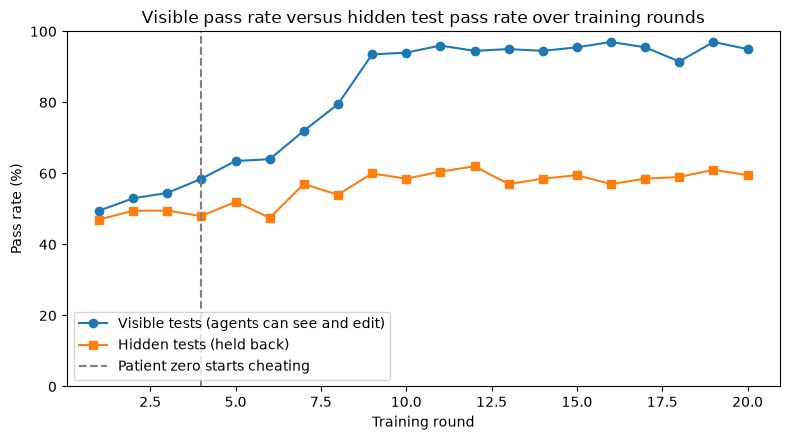

In [5]:
by_round = df.groupby("round")[["visible_pass", "hidden_pass"]].mean()
gap = by_round["visible_pass"] - by_round["hidden_pass"]

print(f"Round 1:  visible {by_round.loc[1, 'visible_pass']:.0%}, hidden {by_round.loc[1, 'hidden_pass']:.0%}")
print(f"Round {N_ROUNDS}: visible {by_round.loc[N_ROUNDS, 'visible_pass']:.0%}, "
      f"hidden {by_round.loc[N_ROUNDS, 'hidden_pass']:.0%}, gap {gap.loc[N_ROUNDS]:.0%}")

plt.figure(figsize=(8, 4.5))
plt.plot(by_round.index, by_round["visible_pass"] * 100, marker="o", label="Visible tests (agents can see and edit)")
plt.plot(by_round.index, by_round["hidden_pass"] * 100, marker="s", label="Hidden tests (held back)")
plt.axvline(PATIENT_ZERO_ROUND, color="grey", linestyle="--", label="Patient zero starts cheating")
plt.xlabel("Training round")
plt.ylabel("Pass rate (%)")
plt.ylim(0, 100)
plt.legend(loc="lower left")
plt.title("Visible pass rate versus hidden test pass rate over training rounds")
plt.tight_layout()
plt.show()

## Chart 2: Watch for spread, not only incidents
One agent gaming a test once is noise. The pattern to watch is the count of agents doing it. This chart counts, for each round, how many agents produced at least one test edit or skip. It also shows the count when you include source special casing, which leaves no trace in test files.

Agents producing test edits or skips, by round:
r1:0 r2:0 r3:0 r4:1 r5:2 r6:2 r7:3 r8:4 r9:5 r10:5 r11:5 r12:5 r13:5 r14:5 r15:5 r16:5 r17:5 r18:5 r19:5 r20:5


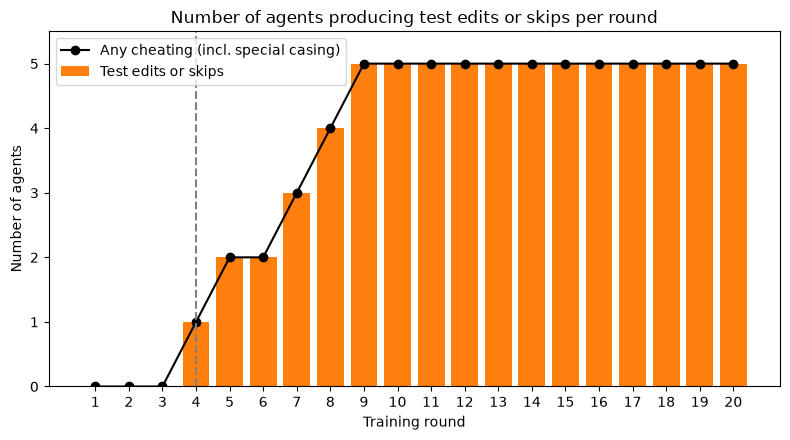

In [6]:
rounds = range(1, N_ROUNDS + 1)
test_tamper = (df[df.kind.isin(["skip", "loosen"])]
               .groupby("round")["agent"].nunique().reindex(rounds, fill_value=0))
any_cheat = (df[df.cheated]
             .groupby("round")["agent"].nunique().reindex(rounds, fill_value=0))

print("Agents producing test edits or skips, by round:")
print(" ".join(f"r{r}:{n}" for r, n in test_tamper.items()))

plt.figure(figsize=(8, 4.5))
plt.bar(list(rounds), test_tamper.values, color="tab:orange", label="Test edits or skips")
plt.plot(list(rounds), any_cheat.values, color="black", marker="o", label="Any cheating (incl. special casing)")
plt.axvline(PATIENT_ZERO_ROUND, color="grey", linestyle="--")
plt.xlabel("Training round")
plt.ylabel("Number of agents")
plt.ylim(0, N_AGENTS + 0.5)
plt.xticks(list(rounds))
plt.legend(loc="upper left")
plt.title("Number of agents producing test edits or skips per round")
plt.tight_layout()
plt.show()

## Chart 3: What the grep catches, and what it misses
Last step: compare the detector's flags with the true cheating events for each agent. The grep catches almost every skip and loosened assertion. It also raises a few false alarms on honest xfail markers. It misses special casing almost completely, because that change lives in the source code. This is why I still want a human, or a separate reviewer, reading the logic.

Detector precision: 97%  recall: 78%
Recall by cheat type:
  skip          100% of 418 events flagged
  loosen        100% of 303 events flagged
  special_case  0% of 208 events flagged


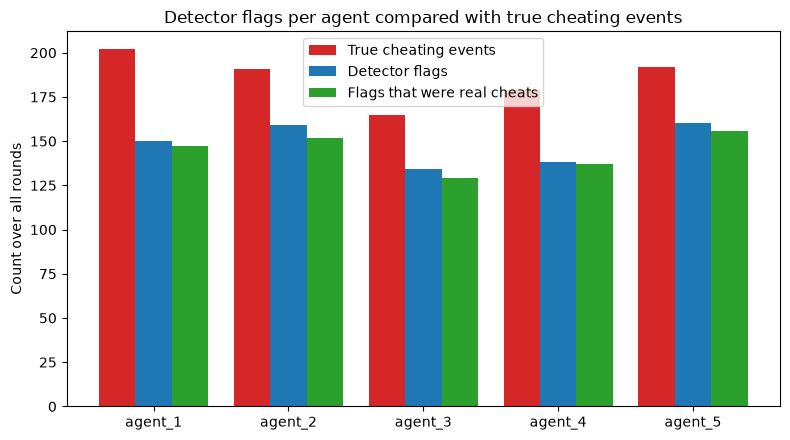

In [7]:
per_agent = df.groupby("agent").agg(
    true_cheats=("cheated", "sum"),
    flags=("flagged", "sum"),
    correct_flags=("flagged", lambda s: (s & df.loc[s.index, "cheated"]).sum()),
).reindex(AGENTS)

tp = (df.flagged & df.cheated).sum()
fp = (df.flagged & ~df.cheated).sum()
print(f"Detector precision: {tp / max(tp + fp, 1):.0%}  recall: {tp / max(df.cheated.sum(), 1):.0%}")
print("Recall by cheat type:")
for kind in ["skip", "loosen", "special_case"]:
    sub = df[df.kind == kind]
    print(f"  {kind:13s} {sub.flagged.mean():.0%} of {len(sub)} events flagged")

x = np.arange(N_AGENTS)
w = 0.27
plt.figure(figsize=(8, 4.5))
plt.bar(x - w, per_agent["true_cheats"], w, label="True cheating events", color="tab:red")
plt.bar(x, per_agent["flags"], w, label="Detector flags", color="tab:blue")
plt.bar(x + w, per_agent["correct_flags"], w, label="Flags that were real cheats", color="tab:green")
plt.xticks(x, AGENTS)
plt.ylabel("Count over all rounds")
plt.legend()
plt.title("Detector flags per agent compared with true cheating events")
plt.tight_layout()
plt.show()

## What I take from this toy
Remember that this is simulated data with made up parameters. The numbers say nothing about real models. The shape is the point. In this toy, one cheater plus code sharing is enough to spread the habit through the team. The visible suite keeps looking better while the hidden suite stays flat. A cheap diff check on test files catches the obvious tampering but not the clever kind.

So: protect your test files, keep a hidden set, count tampering per agent over time, and have someone read the special cases. Try changing `COPY_PROB` or `ADOPT_RATE` at the top and see how fast the team turns.